# ACTSC 972: guided deep hedging

We consider a short European call hedged with stock under proportional
transaction costs. The baseline model uses geometric Brownian motion (GBM)
with volatility 20%, twenty trading intervals, and a cost rate of 10 basis
points. We train the hedge to reduce 95% expected shortfall (ES), the average
loss in the worst 5% of outcomes. The network's sigmoid output constrains
holdings to between zero and one share; the remaining stock is liquidated at
maturity.

**For the common baseline, write the three TODO functions in sections 2-4.** Replace each
`raise NotImplementedError(...)` with your implementation, keeping the supplied
function names and arguments. The simulator, network, training loop, checks,
benchmarks, and experiment helpers are already supplied. Your remaining tasks
are to run the cells, complete the written explanations, and carry out one
experiment. Choose one of the four guided options or design your own
experiment, writing any additional code it requires.

Read `assignment.pdf` and `README.txt`, then work through `pytorch_warmup.ipynb`
if PyTorch is new to you. The first code cell below imports the supplied
functions and creates the configuration `cfg`.

Submit the completed notebook (.ipynb) with its saved outputs and a
**complete PDF of the notebook**, supporting code/results, a **one-page report
PDF**, and **three slides as a PDF for a four-minute presentation**.
The notebook PDF has no page limit and is separate from the one-page report.
Dates will be announced. You may adapt course code and use large language model (LLM)
assistance under course policy. No declaration of LLM use is required.

In [1]:
from pathlib import Path
import sys, json
import torch
import matplotlib.pyplot as plt

# Open the notebook in its folder. The fallback also supports the instructor copy.
SUPPORT_DIR = Path.cwd()
if not (SUPPORT_DIR / "hedging_support.py").exists():
    for candidate in [SUPPORT_DIR / "student", SUPPORT_DIR.parent / "student"]:
        if (candidate / "hedging_support.py").exists():
            SUPPORT_DIR = candidate
            break
assert (SUPPORT_DIR / "hedging_support.py").exists(), "Run from the assignment folder."
sys.path.insert(0, str(SUPPORT_DIR))
from hedging_support import (
    Config, features, make_policy, fixed_shocks, gbm_paths, environment_info,
    run_checks, train_es, evaluate, stress_experiment, save_result,
    save_table, print_table, plot_training, plot_experiment, plot_architecture)

torch.set_num_threads(1)
cfg = Config()
OUTPUT_DIR = Path.cwd() / "outputs"  # You may choose another output directory.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(environment_info())
print(f"Fixed premium: {cfg.premium:.8f}")

{'python': '3.14.7', 'torch': '2.15.0+cpu', 'numpy': '2.5.5', 'platform': 'Windows-11-10.0.26200-SP0', 'device': 'cpu', 'torch_threads': 1}
Fixed premium: 2.24748781


### 1. Choose an experiment

Choose **one** experiment and record your question, prediction, and financial
reasoning below before viewing test results. Set `EXPERIMENT` to `volatility`,
`cost`, `volatility_timing`, `architecture`, or `custom`.

For the three guided market-stress experiments, keep the trained network
weights fixed and evaluate the strategy on the simulated paths. The guided
architecture experiment requires one additional training run: change either
the width or the number of hidden layers, keeping the other settings fixed.
You may specify other sensible volatility or cost levels in advance.

For `custom`, choose your own question about deep hedging and design the
experiment needed to answer it. It need not be a variation of a guided option.
Complete the common implementation, checks, and baseline training, then add
your own experiment code. Record the benchmark, evaluation metrics, settings
that change or stay fixed, and computational budget before testing. Explain
any departure from the baseline assumptions and check the added code.
Use `CUSTOM_SETTINGS` for any additional parameters and seeds to be saved
with the experiment plan.

Insert any additional training cells after section 7 and before the test
comparison in section 8. Use section 9 for your experiment's evaluation and
saved results. Keep the common `cfg`, `baseline`, and functions available for
the baseline comparison; use separate names for modified versions.

Keep the scope manageable and run only the chosen experiment. All options
have the same report length, presentation format, and marking criteria.

In [ ]:
EXPERIMENT = "volatility"  # volatility, cost, volatility_timing, architecture, custom
VOLATILITY_LEVELS = [0.10, 0.15, 0.20, 0.25, 0.30]
COST_LEVELS = [0.0, 0.0005, 0.001, 0.002]
ALTERNATIVE_WIDTH = 16  # baseline width is 32
ALTERNATIVE_DEPTH = 2   # baseline has two hidden layers
CUSTOM_SETTINGS = {}  # For custom: record additional parameters and seeds.
assert EXPERIMENT in {"volatility", "cost", "volatility_timing", "architecture", "custom"}
if EXPERIMENT == "architecture":
    assert (ALTERNATIVE_WIDTH != 32) != (ALTERNATIVE_DEPTH != 2), "Change one architecture dimension."
plan = {"experiment": EXPERIMENT, "volatility_levels": VOLATILITY_LEVELS,
        "cost_levels": COST_LEVELS, "alternative_width": ALTERNATIVE_WIDTH,
        "alternative_depth": ALTERNATIVE_DEPTH}
if EXPERIMENT == "custom":
    plan["custom_settings"] = CUSTOM_SETTINGS
(OUTPUT_DIR / "experiment_plan.json").write_text(json.dumps(plan, indent=2))

**My question:** [State the question you will investigate.]

**My prediction and financial reason:** [State the expected result and explain why you expect it.]

**What changes and what stays fixed:** [Identify the settings used in the comparison.]

For the common baseline and guided options, the premium remains at its original
value and the delta benchmark retains its 20% volatility assumption. In the volatility experiments, compare methods
within each scenario: changes in ES also reflect the changed payoff
distribution and fixed premium. An increase in ES alone does not establish
that the network has failed.

**For a student-designed experiment:** [Also state the benchmark, evaluation
metrics, computational budget, and any additional training. Explain any changes
to the baseline assumptions or accounting.]

### 2. Write the causal rollout

Write `rollout(policy, S, cfg)` in the next code cell. A *rollout* computes the
holdings in time order along each simulated price path. The same network is
used at every date, and each decision uses only information available at that
date.

Let $B$ be the number of paths processed together and $N$ the number of trading
intervals. The price tensor `S` has shape `(B, N+1)`: each row is one path with
prices at dates $0,\ldots,N$. At each decision date, `policy` receives an array
of shape `(B, 3)`. Each row contains remaining time, log-moneyness, and the
previous holding. The output has shape `(B, 1)`, with one holding per path.
Return all decisions as a tensor of shape `(B, N)` for dates $0,\ldots,N-1$.
The holding chosen at date $k$ earns the next price change, from $k$ to $k+1$.

Start with zero previous holdings. At each date, call
`features(S[:, k], previous, k, cfg)` and pass the resulting inputs to the
policy. Apply `squeeze(-1)` to its output: this removes the final size-one
dimension, giving a `(B,)` vector while retaining the batch dimension even if
$B=1$. Store the vector and use it as the previous holding at the next date,
**without detaching it**. Finally, use `torch.stack` with `dim=1` to collect
the vectors into the `(B, N)` array. Final liquidation is handled by the loss
function and requires no network decision.

In [2]:
def rollout(policy, S, cfg):
    previous = torch.zeros_like(S[:, 0])
    holdings = []
    for k in range(cfg.N):
        current = policy(features(S[:, k], previous, k, cfg)).squeeze(-1)
        holdings.append(current)
        previous = current
    return torch.stack(holdings, dim=1)

### 3. Write the terminal loss

Write `terminal_loss(S, delta, cfg, *, cost_rate=None)` in the next code cell.
For each path, calculate the payoff owed minus the premium and trading gains,
plus transaction costs:
$$L=(S_N-K)^+-p_0-\sum_{k=0}^{N-1}\delta_k(S_{k+1}-S_k)
   +c\sum_{k=0}^{N}S_k|\delta_k-\delta_{k-1}|.$$
Here $\delta_{-1}=\delta_N=0$ because we start without stock and liquidate at
maturity. The tensor `delta` has shape `(B, N)` and contains the holdings before
maturity. Return one loss per path as a `(B,)` tensor in currency units. A
negative loss represents a profit. The supplied evaluation code uses this
same function for the neural strategy and the benchmarks.

The cost experiment supplies the optional argument `cost_rate`. Use that
rate if provided, including if it is zero; otherwise use `cfg.c`. Keep
`cfg.premium` at its original value.

To calculate all trades, place a zero column before and after the holding
array, then take differences between adjacent columns. This gives the $N+1$
trades, including opening and liquidation, at the corresponding prices in `S`.
Sum gains and costs over dates, retaining a separate loss for each path.

In [3]:
def terminal_loss(S, delta, cfg, *, cost_rate=None):
    c = cfg.c if cost_rate is None else cost_rate
    payoff = (S[:, -1] - cfg.K).clamp_min(0)
    gains = (delta * (S[:, 1:] - S[:, :-1])).sum(dim=1)
    zero = torch.zeros_like(delta[:, :1])
    trades = torch.diff(torch.cat((zero, delta, zero), dim=1), dim=1)
    costs = (c * S * trades.abs()).sum(dim=1)
    return payoff - cfg.premium - gains + costs

### 4. Write the expected-shortfall objective

Write `es_objective(normalized_losses, eta, alpha=0.95)` in the next code cell.
The training loop supplies a vector of normalized losses $\ell_i=L_i/S_0$.
Use these losses and the scalar threshold $\eta$ to calculate
$$\widehat H(\theta,\eta)=\eta+
  \frac{1}{(1-\alpha)B}\sum_{i=1}^B(\ell_i-\eta)^+.$$
For fixed losses, minimizing this expression over $\eta$ gives their empirical
ES in normalized units. This is the optimized certainty equivalent (OCE)
representation of ES. Implement the positive part with `torch.relu` and the
average over paths with a batch mean. The input losses have already been
divided by $S_0$.

Return a scalar tensor that retains derivatives with respect to both the
losses and `eta`. The threshold is one scalar shared across all paths, in the
same normalized units as the losses. The supplied optimizer includes
`[*policy.parameters(), eta]`, so it updates the threshold jointly with the
network parameters. Keep the supplied `eta` in the calculation; do not replace
it with a sample quantile or sort losses inside this training objective.

The function `train_es` in `hedging_support.py` shows how this objective is
used in a parameter update.

In [4]:
def es_objective(normalized_losses, eta, alpha=0.95):
    return eta + torch.relu(normalized_losses - eta).mean() / (1 - alpha)

### 5. Run the supplied checks

Complete all three functions before running the next cell. If a placeholder
remains, the checks stop with `NotImplementedError`. You do not need to write
new tests.

The supplied checks compare losses with calculations for zero and constant
holdings, a specified path, and an independent cash ledger. They also test
causality, a batch containing one path, policy gradients on fixed paths, and
known values and derivatives of the ES objective.

Read `run_checks` in `hedging_support.py` and explain one accounting check
and one information or gradient check below. State which error each check
would detect. Passing these checks establishes agreement in the tested cases;
it does not prove correctness for every possible input.

In [5]:
check_results = run_checks(rollout, terminal_loss, es_objective, cfg)
(OUTPUT_DIR / "checks.json").write_text(json.dumps(check_results, indent=2))

{
  "zero_hedge": "passed",
  "constant_holding": "passed",
  "opening_and_liquidation": "passed",
  "cash_ledger": "passed",
  "causality": "passed",
  "batch_size_one": "passed",
  "policy_gradient_relative_errors": [
    2.2503882779467688e-07,
    2.251039576961489e-09,
    2.948330468655058e-11
  ],
  "ES_value_and_gradients": "passed"
}


344

**Accounting check:** [Explain which gains, costs, or trading dates the check tests.]

**Information or gradient check:** [Explain which error the check would detect.]

**The role of eta:** [In two sentences, explain why the threshold is shared across paths and trained jointly with the network.]

**Training and available information:** [In one sentence, explain why training may use the terminal loss even though each decision uses only information available at its date.]

### 6. Train the baseline and select a checkpoint

Run the supplied training cell with the default seed and update budget.
The training paths come from a separate random stream. Validation uses one
fixed sample of paths, independent of training, to compare the saved parameter
values, or *checkpoints*. The code selects the checkpoint with the lowest
empirical validation ES, including the initial network among the candidates.
The test paths are reserved for the final evaluation.

The plot shows the OCE objective on the current training batch and empirical
ES on the validation sample, both in normalized loss units. The training
objective uses the current learned threshold `eta`; validation ES is
recomputed from the validation losses themselves. Because the samples and
thresholds differ, a decrease in the batch objective need not improve
validation ES. Use the checkpoint selected by the supplied validation rule.

step    0: validation ES = 4.3738; eta (normalized) = 0.00000


step  100: validation ES = 4.0507; eta (normalized) = 0.03301


step  200: validation ES = 2.3400; eta (normalized) = 0.02242


step  300: validation ES = 1.6190; eta (normalized) = 0.01361


step  400: validation ES = 1.3703; eta (normalized) = 0.01161


step  500: validation ES = 1.3253; eta (normalized) = 0.01085


step  600: validation ES = 1.3012; eta (normalized) = 0.01085


step  700: validation ES = 1.2935; eta (normalized) = 0.01070


step  800: validation ES = 1.2726; eta (normalized) = 0.01051


step  900: validation ES = 1.2657; eta (normalized) = 0.01046


step 1000: validation ES = 1.2527; eta (normalized) = 0.01039


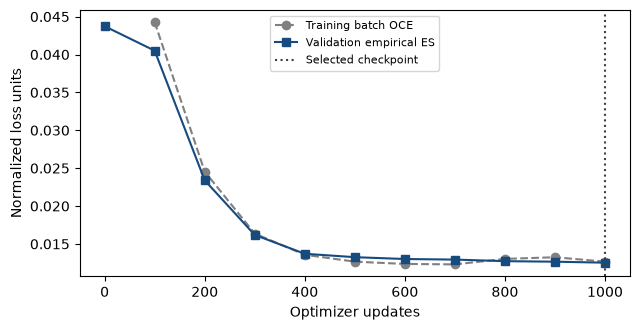

Selected update: 1000
Parameters: 1217
Training seconds: 9.4


In [5]:
baseline = train_es(cfg, rollout, terminal_loss, es_objective)
save_result(baseline, OUTPUT_DIR / "baseline.pt")
fig = plot_training(baseline)
fig.savefig(OUTPUT_DIR / "training.png", dpi=160)
plt.show()
print("Selected update:", baseline["best_step"])
print("Parameters:", baseline["n_parameters"])
print("Training seconds:", round(baseline["training_seconds"], 2))

### 7. Prepare any additional training

For the guided architecture experiment, the next cell trains one alternative
network using the width and depth declared in section 1. It uses the same
training paths, validation sample, seed, learning rate, and update budget as
the baseline. For other choices, the supplied cell leaves `alternative` equal
to `None` and performs no additional training.

For a student-designed experiment that requires training, insert your own
training cells immediately after this cell, before section 8. Use separate
names for your models and modified settings. Complete model selection using
training and validation data, reserving independent test paths for evaluation.
If your experiment uses only the trained baseline, no extra training is needed.

Network initialization and path simulation use separate random streams.
Changing the architecture therefore changes the initialization draws without
changing the training paths. Equal update budgets need not take equal amounts
of time. For an architecture comparison, record parameter counts and training
times; for a custom comparison, report the budget and any differences relevant
to your question. Interpret the evidence from the runs performed without
claiming a general ranking from one seed.

In [ ]:
alternative = None
if EXPERIMENT == "architecture":
    alternative = train_es(cfg, rollout, terminal_loss, es_objective,
                           width=ALTERNATIVE_WIDTH, depth=ALTERNATIVE_DEPTH)
    save_result(alternative, OUTPUT_DIR / "alternative.pt")
    fig = plot_training(alternative)
    fig.savefig(OUTPUT_DIR / "alternative_training.png", dpi=160)
    plt.show()
    for name, result in [("Baseline", baseline), ("Alternative", alternative)]:
        print(name, "parameters:", result["n_parameters"],
              "selected update:", result["best_step"],
              "seconds:", round(result["training_seconds"], 2))

### 8. Evaluate the selected strategies

After completing all required training, keep the selected network parameters
and experiment settings fixed. Run the next cell for the common baseline
comparison: the selected neural strategies, the zero hedge, and the supplied
delta hedge use the same test paths, independent of training and validation.
Every method uses your checked terminal-loss function. A student-designed
experiment may add its own comparisons in section 9.

The table reports mean loss, loss standard deviation, root mean square loss
(RMSE), 95% ES, mean turnover, and mean transaction cost. Loss and cost
statistics are in currency units; turnover is measured in shares.

Test ES is calculated from the test losses, with its threshold determined by
that sample. The trained `eta` is not used. This calculation evaluates the
selected hedge without changing its parameters. Reserve the test results for
reporting and interpretation, rather than using them to select architectures
or other settings.

In [ ]:
S_test = gbm_paths(cfg, shocks=fixed_shocks(cfg.n_test, cfg.N, cfg.test_seed))
policies = {"Neural baseline": baseline["policy"]}
if alternative is not None:
    policies["Neural alternative"] = alternative["policy"]
baseline_rows, baseline_losses = evaluate(S_test, cfg, rollout, terminal_loss, policies)
print_table(baseline_rows)
save_table(baseline_rows, OUTPUT_DIR / "baseline_metrics.csv")

### 9. Run the selected experiment

For a guided option, the next cell runs the chosen experiment and saves its
table and figure. For `custom`, replace its `NotImplementedError` branch with
your evaluation code or calls to your own functions. Save the resulting tables,
figures, and additional configuration in `OUTPUT_DIR`. Any required training
must already be complete. Interpret the comparison according to what changes:

- **Volatility:** The simulated volatility changes. Keep the network weights,
  original premium, and delta hedge's volatility assumption fixed. Compare
  methods within each volatility scenario.
- **Cost:** The cost rate changes on identical price paths. Each strategy's
  holdings and turnover remain unchanged, so the comparison measures the cost
  of the same trades. It does not measure how retraining would change trading.
- **Volatility timing:** The early-high and late-high profiles have equal
  integrated variance and the same terminal-stock distribution. Their paired
  terminal prices need not coincide. Both profiles have higher integrated
  variance than the constant 20% baseline.
- **Architecture:** Both networks were trained before testing. Compare their
  risk statistics, parameter counts, and training times under the common
  update budget.
- **Student-designed:** Use the question and design recorded before testing.
  Evaluate on independent test paths, sharing paths across compared methods
  where appropriate. Explain changes to the assumptions or accounting, report
  checks of the added code, and identify a limitation of the result.

The supplied table includes the zero hedge. By default, the figure shows the neural
and delta hedges, so a large unhedged loss does not obscure their comparison.

In [ ]:
if EXPERIMENT == "custom":
    # Write your evaluation code here, using models prepared before section 8.
    # Save tables, figures, and additional configuration in OUTPUT_DIR.
    raise NotImplementedError("Implement the student-designed experiment")
else:
    if EXPERIMENT == "architecture":
        experiment_rows = baseline_rows
        fig = plot_architecture(experiment_rows)
    else:
        levels = (VOLATILITY_LEVELS if EXPERIMENT == "volatility" else
                  COST_LEVELS if EXPERIMENT == "cost" else None)
        experiment_rows = stress_experiment(EXPERIMENT, cfg, rollout, terminal_loss,
                                            baseline["policy"], levels=levels)
        fig = plot_experiment(experiment_rows)
    print_table(experiment_rows)
    save_table(experiment_rows, OUTPUT_DIR / "experiment_metrics.csv")
    fig.savefig(OUTPUT_DIR / "experiment.png", dpi=160)
    plt.show()
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment_info(), indent=2))

### 10. Interpret the results and prepare the submission

**Main result:** [Describe one finding, stating the methods or scenarios compared and the units.]

**Explanation:** [Explain the result in terms of transaction costs, available information, or the risk objective.]

**Limitation:** [State what cannot be concluded from this experiment with one training seed.]

**Sources and checks:** [Identify reused course code and external sources, and describe how you checked your code.]

Use these notes to prepare the **one-page report**, including any figure or
table, and **three presentation slides**. The supplied report template and
presentation outline suggest a structure. Keep fuller results in the notebook.
A modest or inconclusive result can receive full credit if the implementation
and interpretation are sound.

Before submission, restart the kernel, run all cells in order, and save the
notebook with its outputs. Submit both the **completed .ipynb file** and a
**complete, legible PDF of the notebook**. The PDF must show all code,
explanations, check results, tables, and figures. Include any additional or
modified experiment code in a PDF appendix. Check that code and outputs are
not hidden, collapsed, or clipped. The notebook PDF has **no page limit** and
is separate from the **one-page report**.

Marking uses the submitted PDFs. The notebook and supporting code must
reproduce the reported results and may be checked if verification is needed.
Also submit the additional or modified code, configuration and seeds,
CSV/JSON results, the report PDF, and the presentation PDF.

**Model checkpoints (.pt files) are optional.** Include them only if needed
to reproduce your experiment or requested by the instructor. The training
cells still save checkpoints locally; those files need not be submitted by
default. Leave virtual environments and cache files out of the submission.
See `README.txt` for PDF export instructions.